## Onset of movement: max and target speed (development)

Analyses of movement onset.
Maximum speed and target speed across development.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
#from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d
from functions.MC_utilities import *

from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import matplotlib.cm as cm

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

In [3]:
print(os.getcwd()) 

<repo>/code/onset_speed


In [4]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("onset_speed"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


#### Import data:

In [5]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3, 4]


In [6]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [7]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
#fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[16, 17, 18, 19, 20, 21]


In [8]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [9]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [10]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [11]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 27, 28, 30, 34, 34]


Load:

In [12]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [13]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [15]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [16]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [17]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [18]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:02<01:01,  2.92s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:05<00:55,  2.77s/it]

...

 91%|█████████ | 20/22 [00:58<00:05,  2.90s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:01<00:02,  2.93s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:04<00:00,  2.92s/it]


In [19]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:05,  3.11s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:05<00:58,  2.91s/it]

...

 91%|█████████ | 20/22 [00:58<00:05,  2.89s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:00<00:02,  2.83s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:03<00:00,  2.88s/it]


In [20]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 22/22 [00:00<00:00, 141.54it/s]


Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 27_12Jun24_1
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


## start some plots to visualize data

In [21]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

14_31Oct24_1


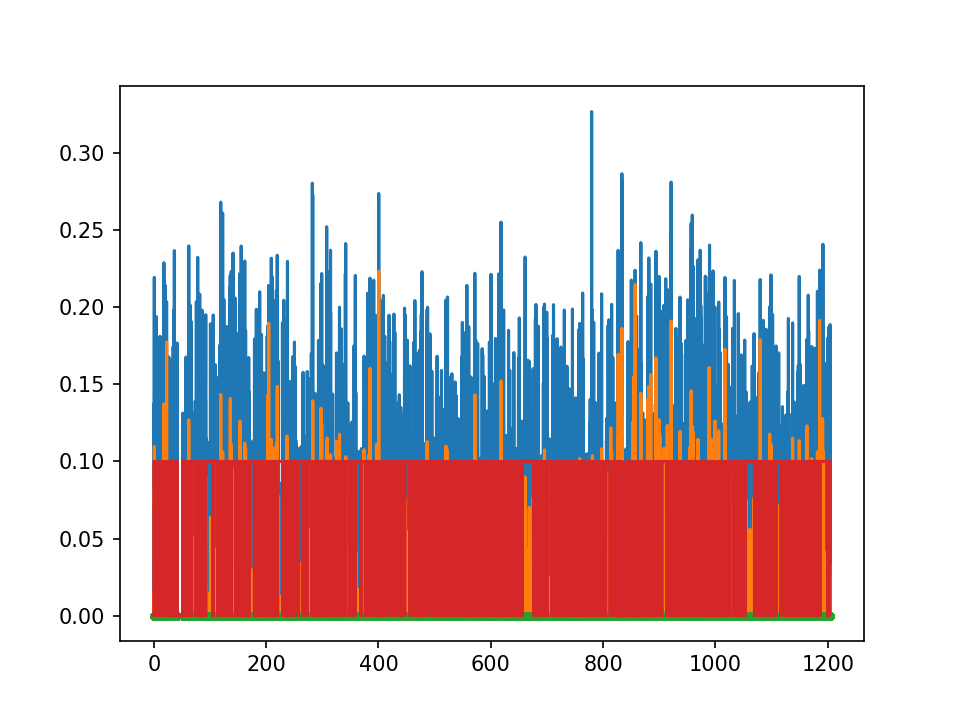

In [22]:
i=4

print(fish_ids[i])

dt=1/300
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
#ax.plot(t_c_list[i],dangletail_c_list[i]/10,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
#ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

ax.plot(t_c_list[i],mask_movetail_list[i]/10,'-')

#ax.set_xlim(255,255.5)
plt.show()

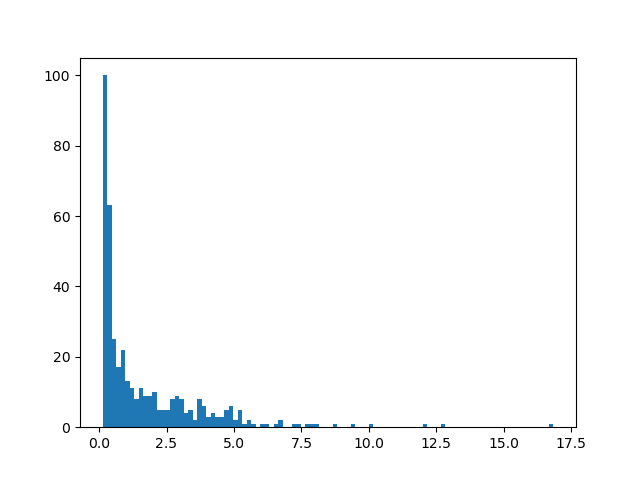

In [23]:
plt.figure(dpi=100)
plt.hist(bout_duration_list[i], bins=100)
plt.show()

In [26]:
len(mask_movetail_list[i])

361286

In [27]:
len(vfish_c_list[i])

361286

1.8880372014510913


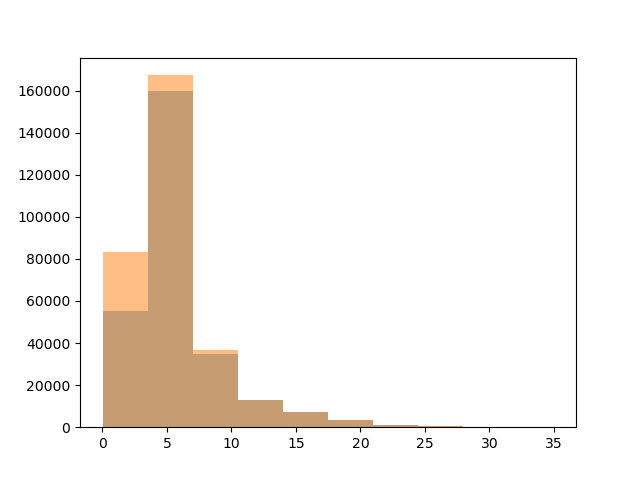

In [28]:
plt.figure()
plt.hist(vfish_c_list[i][mask_movetail_list[i]], alpha = 0.5)
plt.hist(vfish_c_list[i], alpha = 0.5)
#plt.hist(vfish_c_list[i][~mask_movetail_list[i]])
print(np.nanmedian(vfish_c_list[i][~mask_movetail_list[i]]))
plt.show()

# onset

In [29]:
n = 18
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=33):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    t_end=t_c_list[i][onset_indices_list[i][n+1]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_end)
    ax.plot(t_c_list[i][indices]-t_onset,10*vfish_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],color='gray')
    ax.set_xlim(-t_before,1)

    plt.show()

interactive(children=(IntSlider(value=33, description='n', max=413), Output()), _dom_classes=('widget-interact…

## DEF maxV, targetV

In [35]:
from scipy.ndimage import gaussian_filter1d

Max_vfish_c_onsets_tot = [[] for _ in range(len(onset_indices_list))]
Maxt_vfish_c_onsets_tot = [[] for _ in range(len(onset_indices_list))]
target_vfish_c_onsets_tot = [[] for _ in range(len(onset_indices_list))]

for i in range(len(onset_indices_list)):
    v_max_fish = []
    t_v_max_fish = []
    v_target_fish = []
    for n in range(len(onset_indices_list[i])-1):
            t_onset=t_c_list[i][onset_indices_list[i][n]]
            t_end= t_onset + t_c_list[i][onset_indices_list[i][n+1]]
            indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_end)
            
            time_seg = t_c_list[i][indices]
            v_seg = vfish_c_list[i][indices]
            v_seg_gf = gaussian_filter1d(v_seg, sigma=10)
            
            max_idx = np.argmax(v_seg_gf[:150])
            v_max = v_seg_gf[max_idx]
            t_v_max = time_seg[max_idx]
            
            v_target = np.nanmean(v_seg_gf)
            
            #th_noise_vfish = np.nanmedian(vfish_c_list[i][~mask_movetail_list[i]])
            #if v_max>th_noise_vfish:
            v_max_fish.append(v_max)
            t_v_max_fish.append(t_v_max)
            v_target_fish.append(v_target)
                
    Max_vfish_c_onsets_tot[i] = v_max_fish
    Maxt_vfish_c_onsets_tot[i] = t_v_max_fish
    target_vfish_c_onsets_tot[i] = v_target_fish
    

In [ ]:
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=34):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)

    t_onset=t_c_list[i][onset_indices_list[i][n]]
    t_end=t_c_list[i][onset_indices_list[i][n+1]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_end)
    ax.plot(t_c_list[i][indices], vfish_c_list[i][indices],'.-',alpha=0.6)

    ax.plot(Maxt_vfish_c_onsets_tot[i][n], Max_vfish_c_onsets_tot[i][n], 'o')
    ax.axhline(target_vfish_c_onsets_tot[i][n],color='red')

    plt.show()

interactive(children=(IntSlider(value=34, description='n', max=213), Output()), _dom_classes=('widget-interact…

/var/folders/xl/ytwdm9h57dd5l_2fzzwzj7hw0000gn/T/ipykernel_9094/3944516567.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('viridis')


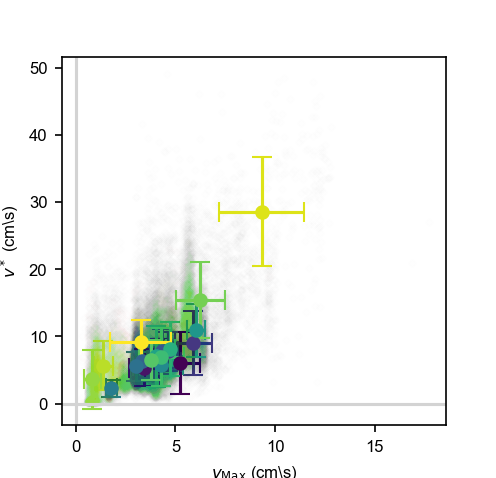

In [ ]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2*2
fig_height_cm = 4.05*2

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)


eta_list = [0, 1, 2, 8, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 17, 15, 16, 18, 19]
eta_norm = (eta_list - np.min(eta_list)) / (np.max(eta_list) - np.min(eta_list))  # Normalize to 0–1

cmap = cm.get_cmap('viridis')


# Loop through each i
for i in range(len(eta_list)):
    color = cmap(eta_norm[i])#cmap(i)
    plt.plot(target_vfish_c_onsets_tot[i], Max_vfish_c_onsets_tot[i], '.',color=color, alpha = 0.005)

    # If each i is a single value:
    x_vals = target_vfish_c_onsets_tot[i] 
    y_vals = Max_vfish_c_onsets_tot[i]

    x = np.nanmean(x_vals)
    y = np.nanmean(y_vals)
    x_err = np.nanstd(x_vals)
    y_err = np.nanstd(y_vals)


    # Plot the point with error bars
    plt.errorbar(x, y, xerr=x_err, yerr=y_err, fmt='o', color=color,
                 ecolor=color, alpha=1, capsize=5)

# Axis formatting
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlabel(r'$v_{\mathrm{Max}}$ (cm\s)')
plt.ylabel(r'$v^*$ (cm\s)')

#plt.xlim(-1, 40)
#plt.xticks([0, 20, 40], [0, 2, 4]) #(cm\s)
#plt.ylim(-1, 20)
#plt.yticks([0, 20, 40], [0, 2, 4]) #(cm\s)

#fig.savefig(os.path.join(path_figures, "max_target_speed_all_fish.pdf"), format="pdf")


plt.show()

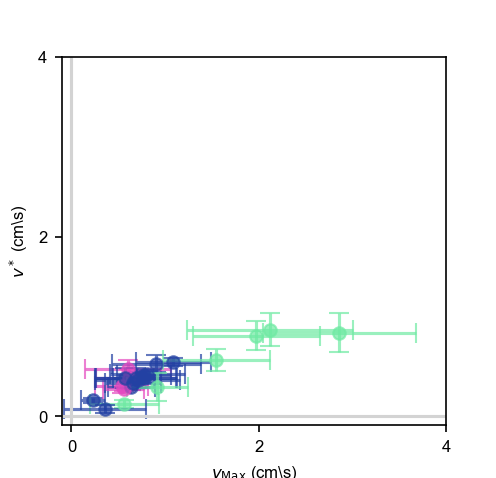

In [33]:
index_cont = [0, 1, 2, 8]
index_mix = [3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 17]
index_bout = [15, 16, 18, 19]

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2*2
fig_height_cm = 4.05*2

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# Loop through each i
for i in range(len(Max_vfish_c_onsets_tot)):
    if i in index_cont:
        color = color_low_boutID
    elif i in index_mix:
        color = color_med_boutID
    else:
        color = color_high_boutID
        
    #plt.plot(Max_vfish_c_onsets_tot[i], target_vfish_c_onsets_tot[i], '.',color='black', alpha = 0.02)

    # If each i is a single value:
    x_vals = Max_vfish_c_onsets_tot[i]
    y_vals = target_vfish_c_onsets_tot[i]

    x = np.nanmean(x_vals)
    y = np.nanmean(y_vals)
    x_err = np.nanstd(x_vals)
    y_err = np.nanstd(y_vals)


    # Plot the point with error bars
    plt.errorbar(x, y, xerr=x_err, yerr=y_err, fmt='o', color=color,
                 ecolor=color, alpha=0.7, capsize=5, markersize=6)

# Axis formatting
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlabel(r'$v_{\mathrm{Max}}$ (cm\s)')
plt.ylabel(r'$v^*$ (cm\s)')

plt.xlim(-1, 40)
plt.xticks([0, 20, 40], [0, 2, 4]) #(cm\s)
plt.ylim(-1, 40)
plt.yticks([0, 20, 40], [0, 2, 4]) #(cm\s)

#fig.savefig(os.path.join(path_figures, "max_target_speed_all_fish.pdf"), format="pdf")


plt.show()

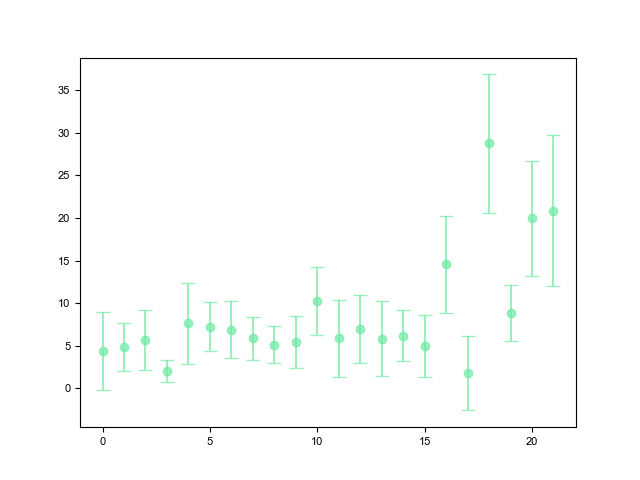

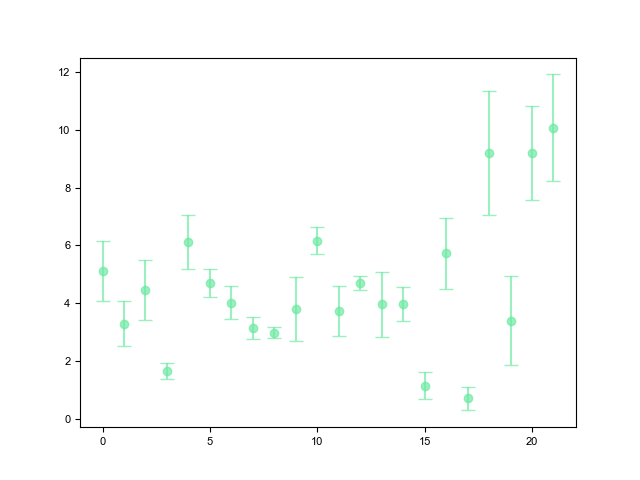

In [34]:
plt.figure()
for i in range(len(Max_vfish_c_onsets_tot)):
    x_vals = Max_vfish_c_onsets_tot[i]
    y_vals = target_vfish_c_onsets_tot[i]

    x = np.nanmedian(x_vals)
    x_err = np.nanstd(x_vals)

    plt.errorbar(i, x, yerr=x_err, fmt='o', color=color,
                 ecolor=color, alpha=0.7, capsize=5, markersize=6)
    
plt.show()
    
    
plt.figure()
for i in range(len(Max_vfish_c_onsets_tot)):
    x_vals = Max_vfish_c_onsets_tot[i]
    y_vals = target_vfish_c_onsets_tot[i]

    y = np.nanmedian(y_vals)
    y_err = np.nanstd(y_vals)

    plt.errorbar(i, y,  yerr=y_err, fmt='o', color=color,
                 ecolor=color, alpha=0.7, capsize=5, markersize=6)
    
plt.show()
